# Example: A Self-Activating Gene Switch
Cells switch genes on and off in response to chemicals in their surroundings. Some genes stay on after the chemical is gone, because the protein made from the gene switches the same gene on. This kind of gene works like a switch with memory.

In this example, we build three small gene networks from configuration files and compute the eigenvalues at their steady states. Then we linearize the self-activating gene about its low steady state, solve the linear model with the S4 recursion, and compare the result with the nonlinear model.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Build gene network models from configuration files:__ A configuration file lists the genes of a network, the rate constants of each gene, and how each gene is regulated. We'll build three small networks from these files and compare the eigenvalues at their steady states.
> * __Classify the steady states of a self-activating gene:__ A gene whose protein activates its own transcription can have three steady states. We'll derive the Jacobian of its balances by hand, check it against a numerical Jacobian, and classify each steady state from its eigenvalues.
> * __Find where the linear model fails:__ The linear model describes small deviations from a steady state. We'll solve it with the S4 recursion for a small and a large pulse of an added chemical, and compare each response with the nonlinear model.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths from this notebook's local setup file -
include(joinpath(@__DIR__, "Include.jl"));

# Choose one theme; after changing it, rerun this cell and the plotting cells -
theme(:default)   # light background
# theme(:dark)   # dark background

In addition to standard Julia libraries, we'll use [the `VLDataScienceMachineLearningPackage.jl` package](https://github.com/varnerlab/VLDataScienceMachineLearningPackage.jl). Check out [the documentation](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/) for more information on the functions, types, and data used in this material.

The gene network functions are in [the `GeneNetworks.jl` file](../../../code/src/GeneNetworks.jl) of the course package, and the three network files are in [the `motifs` folder](../../../code/src/data/motifs).

___

## Gene Expression and Its Model
A cell stores the instructions for making its proteins in its __DNA__. A __gene__ is the stretch of DNA that holds the instructions for one protein. Proteins do most of the work in a cell, such as speeding up chemical reactions and switching genes on and off.

A cell makes a protein in two steps. In __transcription__, an enzyme called __RNA polymerase__ copies the gene into a messenger molecule, the __mRNA__. In __translation__, the cell reads the mRNA and builds the __protein__.

Transcription starts at the __promoter__, a short stretch of DNA next to the gene where RNA polymerase binds. A __transcription factor__ is a protein that binds the promoter, and either helps RNA polymerase bind (an __activator__) or blocks it (a __repressor__).

An __inducer__ is a small molecule that binds a transcription factor and changes how well the factor binds the promoter. We add the inducer to the cells from outside. The inducer concentration $I$ (µM) is the input of our models.

### mRNA and Protein Balances
We follow the gene expression model of a chapter by J. D. Varner, in preparation for _Comprehensive Biotechnology_ (4th edition). For each gene $j$, we write a balance on the mRNA concentration $m_{j}$ and the protein concentration $p_{j}$, both in µM:

$$
\begin{aligned}
\frac{dm_{j}}{dt} &= r_{X,j}\,\bar{u}_{j}-(\theta_{m,j}+\mu)\,m_{j}\\
\frac{dp_{j}}{dt} &= r_{L,j}\,w_{j}-(\theta_{p,j}+\mu)\,p_{j}
\end{aligned}
$$

The first term of each balance is production, and the second is loss. The transcription rate $r_{X,j}$ and the translation rate $r_{L,j}$ are the rates at full activity. The transcriptional control $\bar{u}_{j}$ and the translational control $w_{j}$ lie between $0$ and $1$ and scale those rates down.

Loss has two parts. The cell degrades mRNA and protein with the first-order constants $\theta_{m,j}$ and $\theta_{p,j}$ (units: `1/min`), computed from half-lives as $\theta=\ln 2/t_{1/2}$. The cell also grows and divides, which dilutes its contents at the specific growth rate $\mu=\ln 2/t_{d}$, where $t_{d}$ is the doubling time.

The rates follow saturation kinetics:

$$
r_{X,j}=V^{\max}_{X,j}\,\frac{G_{j}}{K_{X,j}+G_{j}},\qquad
r_{L,j}=V^{\max}_{L,j}\,\frac{m_{j}}{K_{L,j}+m_{j}}
$$

where $G_{j}$ is the gene concentration (µM), $V^{\max}$ is a maximum rate (units: `µM/min`), and $K$ is a saturation constant (µM). The transcription rate is constant, because the gene concentration is constant. The translation rate grows with the mRNA level and levels off.

### Promoter States and the Control
The transcriptional control $\bar{u}_{j}$ is the probability that the promoter of gene $j$ is in a state that permits transcription. We list the states of the promoter and give each state $s$ a weight $\omega_{s}$ ([Moon et al., 2012](https://doi.org/10.1038/nature11516); [Adhikari et al., 2020](https://doi.org/10.3389/fbioe.2020.539081)):

$$
\bar{u}_{j}=\frac{\sum_{s\in\mathcal{A}_{j}}\omega_{s}}{1+\sum_{s\in\mathcal{S}_{j}}\omega_{s}},\qquad
\omega_{s}=W_{s}\prod_{b\in s}f_{b},\qquad
f_{b}=\frac{a_{b}^{n}}{K^{n}+a_{b}^{n}}
$$

The empty promoter is the reference state, with weight $1$. The set $\mathcal{S}_{j}$ holds the other states, and the __active__ states $\mathcal{A}_{j}\subseteq\mathcal{S}_{j}$ are those with RNA polymerase bound. Active states count in the numerator and the denominator, and inactive states, such as a promoter blocked by a repressor, count only in the denominator.

Each weight is a constant $W_{s}$ times the bound fraction $f_{b}$ of each transcription factor $b$ bound in state $s$. Here $a_{b}$ is the concentration of the factor that can bind, $K$ is the concentration at which the factor is bound half of the time, and the exponent $n$ sets how steeply binding rises with $a_{b}$.

An inducer changes the concentration that can bind. When the inducer activates its factor, $a_{b}=p_{b}f_{I}$, where $p_{b}$ is the concentration of the factor protein (µM).

The fraction of the factor that carries the inducer is $f_{I}=I^{n_{I}}/(K_{I}^{n_{I}}+I^{n_{I}})$. Here $K_{I}$ is the inducer concentration at which half of the factor carries the inducer (µM), and $n_{I}$ sets how steeply that fraction rises with $I$.

The state with RNA polymerase bound alone transcribes the gene with no activator present. This small basal rate of transcription is the __leak__. The balances therefore need no separate leak term.

The translational control $w_{j}$ follows the same rule, with states of the mRNA. None of our networks regulate translation, which gives $w_{j}=1$.

### Network Motifs
A __network motif__ is a small pattern of regulation that appears in gene networks far more often than in random networks ([Shoval and Alon, 2010](https://doi.org/10.1016/j.cell.2010.09.050)). We'll use three motifs.

<style>
  .course-diagram { color-scheme: light dark; }
  :host-context(body[data-vscode-theme-kind="vscode-light"]) .course-diagram,
  :host-context(body[data-vscode-theme-kind="vscode-high-contrast-light"]) .course-diagram,
  body[data-vscode-theme-kind="vscode-light"] .course-diagram,
  body[data-vscode-theme-kind="vscode-high-contrast-light"] .course-diagram { color-scheme: light; }
  :host-context(body[data-vscode-theme-kind="vscode-dark"]) .course-diagram,
  :host-context(body[data-vscode-theme-kind="vscode-high-contrast"]) .course-diagram,
  body[data-vscode-theme-kind="vscode-dark"] .course-diagram,
  body[data-vscode-theme-kind="vscode-high-contrast"] .course-diagram { color-scheme: dark; }
  body[data-jp-theme-light="true"] .course-diagram { color-scheme: light; }
  body[data-jp-theme-light="false"] .course-diagram { color-scheme: dark; }
  @media print { .course-diagram { color-scheme: only light !important; } }
</style>
<p align="center">
    <img class="course-diagram" src="figs/Fig-Motifs/Fig-Motifs.svg" width="640" style="max-width:100%; height:auto;" alt="Three gene network motifs drawn as circles. Left, negative autoregulation: a circle labeled X with a red loop from X back to X that ends in a flat bar. Middle, positive autoregulation: a circle labeled X with a blue loop from X back to X that ends in an arrowhead. Right, negative feedback loop: circles X and Y, a blue arrow from X to Y, and a red line from Y back to X that ends in a flat bar."/>
</p>

__Three network motifs.__ Each circle is a gene and its protein. A blue arrow is activation, and a red line with a flat end is repression.

* __Negative autoregulation:__ Protein X represses its own gene. This motif speeds up the response of the gene and reduces the differences in protein level between cells.
* __Positive autoregulation:__ Protein X activates its own gene. This motif slows the response, and with steep enough activation it gives all-or-none behavior, in which the gene is either nearly off or fully on.
* __Negative feedback loop:__ Protein X activates gene Y, and protein Y represses gene X. This motif can create oscillations.

___

## Task 1: Three Motifs and Their Eigenvalues
In this task, we build the three motif networks from their configuration files, find a steady state of each network, and compute the eigenvalues of the Jacobian at that steady state.

Each network is a [TOML](https://toml.io/en/) file. The file sets the half-lives and the doubling time, then lists each gene with its rate constants and its promoter states.

[The `motif_path(...)` function](../../../code/src/GeneNetworks.jl) returns the path of a network file in the course package. Let's look at the file for positive autoregulation:

In [2]:
# print the configuration file of the positive autoregulation network -
print(read(motif_path("positive-autoregulation"), String))

# Positive autoregulation: protein X activates transcription of its own gene.
# The activator binds only when it carries the inducer I, so I sets how much X can bind.
#
# With these values, at the baseline inducer I = 1 µM, the gene has three steady states:
#   low   p* ≈ 0.0113 µM, eigenvalues ≈ (−0.292, −0.028) 1/min: stable
#   mid   p* ≈ 0.0583 µM, eigenvalues ≈ (−0.354, +0.034) 1/min: a saddle
#   high  p* ≈ 0.884 µM,  eigenvalues ≈ (−0.289, −0.031) 1/min: stable
# A 60 min inducer pulse to 2 µM returns the gene to the low state; a pulse to 5 µM or more
# switches it to the high state, where it stays after the pulse ends.

[metadata]
description = "Positive autoregulation: protein X activates transcription of its own gene"
reference = "Shoval and Alon, Cell 143 (2010), doi:10.1016/j.cell.2010.09.050"

[parameters]
mRNA_half_life = 2.5      # min
protein_half_life = 35.0  # min
doubling_time = 60.0      # min

[[genes]]
name = "X"
G = 0.005          # gene concentration (µM)
Vmax_X

Promoter state 1 is RNA polymerase bound alone, which gives the leak. In state 2, RNA polymerase binds together with protein X, and only X that carries the inducer $I$ can bind.

[The `build(...)` function](../../../code/src/Factory.jl) reads a network file into a `MyGeneNetworkModel`, and [the `equations(...)` function](../../../code/src/GeneNetworks.jl) prints the balances that the builder made from the file. Let's build all three networks, and print the balances of positive autoregulation:

In [3]:
models = let

    # initialize -
    names = ["negative-autoregulation", "positive-autoregulation", "negative-feedback-loop"]; # the three network files
    models = Dict{String, MyGeneNetworkModel}(); # network name => model

    # build each model from its configuration file -
    for name ∈ names
        path = motif_path(name); # the path of the file in the course package
        models[name] = build(MyGeneNetworkModel, path);
    end

    # print the balances of the positive autoregulation network -
    println(equations(models["positive-autoregulation"]))

    models; # return
end;

Positive autoregulation: protein X activates transcription of its own gene

dm_X/dt = r_X,X ū_X − (θ_m,X + μ) m_X
dp_X/dt = r_L,X w_X − (θ_p,X + μ) p_X
  r_X,X = 0.04 × 0.005 / (0.005 + 0.005) = 0.02 µM/min
  r_L,X = 0.05 m_X / (0.05 + m_X)
  θ_m,X + μ = 0.2888 1/min,  θ_p,X + μ = 0.03136 1/min
  ū_X = (0.005 + 10.0 f₁) / (1 + 0.005 + 10.0 f₁)
    f₁ = a^3.0 / (0.04^3.0 + a^3.0),  a = p_X × I^1.0 / (10.0^1.0 + I^1.0)
  w_X = 1 (not regulated)



The leak weight $0.005$ keeps the gene barely on when protein X is absent. The activator state, with weight $10$, turns the gene nearly fully on once enough X binds.

[The `steady_state(...)` function](../../../code/src/GeneNetworks.jl) finds a steady state with Newton's method from a starting guess, and [the `jacobian(...)` function](../../../code/src/GeneNetworks.jl) computes the Jacobian by central differences.

Positive autoregulation has three steady states, and Newton's method finds one near its starting guess. We start Newton's method near the middle steady state, which Task 2 locates. Let's tabulate each steady state and the eigenvalues there:

In [4]:
let

    # initialize: a starting guess for each network, the mRNA levels then the protein levels (µM) -
    names = ["negative-autoregulation", "positive-autoregulation", "negative-feedback-loop"];
    guesses = Dict(
        "negative-autoregulation" => [0.01, 0.1],
        "positive-autoregulation" => [0.002, 0.06], # near the middle steady state
        "negative-feedback-loop" => [0.05, 0.05, 0.05, 0.05],
    );
    table = Matrix{Any}(undef, length(names), 3); # one row for each network
    converged = Bool[]; # did Newton's method converge for each network?

    # find each steady state, and the eigenvalues of the Jacobian there -
    for i ∈ 1:length(names)
        model = models[names[i]];
        result = steady_state(model; guess = guesses[names[i]]); # Newton's method
        push!(converged, result.converged);
        N = length(model.genes); # the number of genes; the state is [m₁, ..., m_N, p₁, ..., p_N]
        λ = eigvals(jacobian(model, result.x, 0.0)); # the eigenvalues of the Jacobian (1/min)
        table[i, 1] = names[i];
        table[i, 2] = join(string.(round.(result.x[(N + 1):end]; sigdigits = 3)), "
"); # the protein levels, one per line
        table[i, 3] = join(string.(round.(λ; sigdigits = 3)), "
"); # the eigenvalues, one per line
    end

    # show the table -
    pretty_table(table; backend = :text, column_labels = ["network", "steady-state protein (µM)", "eigenvalues (1/min)"], alignment = :l,
        line_breaks = true, table_format = TextTableFormat(horizontal_lines_at_data_rows = :all))

    # checks -
    @test all(converged)
end

┌─────────────────────────┬───────────────────────────┬─────────────────────┐
│ network                 │ steady-state protein (µM) │ eigenvalues (1/min) │
├─────────────────────────┼───────────────────────────┼─────────────────────┤
│ negative-autoregulation │ 0.503                     │ -0.285              │
│                         │                           │ -0.0354             │
├─────────────────────────┼───────────────────────────┼─────────────────────┤
│ positive-autoregulation │ 0.0582                    │ -0.354              │
│                         │                           │ 0.0335              │
├─────────────────────────┼───────────────────────────┼─────────────────────┤
│ negative-feedback-loop  │ 0.0589                    │ -0.31 - 0.077im     │
│                         │ 0.254                     │ -0.31 + 0.077im     │
│                         │                           │ -0.0101 - 0.077im   │
│                         │                           │ -0.0101 

Test Passed

Each network shows a different eigenvalue case:

* __Negative autoregulation:__ Both eigenvalues are real and negative, which makes the steady state a stable node.
* __Positive autoregulation:__ The middle steady state has one positive eigenvalue, which makes it a saddle.
* __Negative feedback loop:__ The four eigenvalues form two complex pairs with negative real parts. The proteins oscillate as they settle, with a period of about $2\pi/0.077\approx 80$ min.

For one gene, the diagonal entries of the Jacobian are the loss terms $-\gamma_{m}=-(\theta_{m}+\mu)$ and $-\gamma_{p}=-(\theta_{p}+\mu)$, which makes its trace $\tau$ negative. A complex pair has the real part $\tau/2$, which is negative. A one-gene model therefore never has purely imaginary eigenvalues.

Steep repression can still give negative autoregulation a complex pair. The eigenvalues are complex when the product of the off-diagonal entries, $A_{12}A_{21}$, falls below $-(\gamma_{m}-\gamma_{p})^{2}/4\approx -0.017\ \mathrm{min}^{-2}$. In our file, that product is about $-0.001\ \mathrm{min}^{-2}$, which keeps both eigenvalues real.

___

## Task 2: The Self-Activating Gene in Detail
In this task, we find the three steady states of the self-activating gene from its nullclines, derive its Jacobian by hand, and classify each steady state from its eigenvalues.

### Nullclines
The gene has one mRNA level $m$ and one protein level $p$, with the loss constants $\gamma_{m}=\theta_{m}+\mu$ and $\gamma_{p}=\theta_{p}+\mu$. A __nullcline__ is the curve on which one balance is zero:

$$
m = \frac{r_{X}\,\bar{u}(p)}{\gamma_{m}}\quad\text{(mRNA nullcline, }dm/dt=0\text{)},\qquad
p = \frac{r_{L}(m)}{\gamma_{p}}\quad\text{(protein nullcline, }dp/dt=0\text{)}.
$$

The steady states are the points where the two nullclines cross. Along the mRNA nullcline, the protein balance becomes one equation in $p$.

We scan that equation for sign changes on a grid of protein levels, and refine each one with Newton's method. [The `transcription_control(...)` function](../../../code/src/GeneNetworks.jl) computes $\bar{u}(p)$:

In [5]:
par_states = let

    # initialize -
    model = models["positive-autoregulation"];
    gene = model.genes[1]; # the one gene, X
    γ_m = gene.θ_m + model.μ; # the mRNA loss constant (1/min)
    γ_p = gene.θ_p + model.μ; # the protein loss constant (1/min)
    r_X = gene.Vmax_X * gene.G / (gene.K_X + gene.G); # the transcription rate (µM/min)
    protein_grid = 10.0 .^ range(-4, 1, length = 2001); # protein levels from 1e-4 to 10 µM, evenly spaced on a log scale

    # the protein balance along the mRNA nullcline, at each protein level -
    g = zeros(length(protein_grid));
    for k ∈ 1:length(protein_grid)
        p = protein_grid[k];
        m = r_X * transcription_control(model, 1, [0.0, p], 0.0) / γ_m; # the mRNA nullcline; the control depends only on p
        r_L = gene.Vmax_L * m / (gene.K_L + m); # the translation rate at this mRNA level (µM/min)
        g[k] = r_L - γ_p * p; # zero at a steady state
    end

    # each sign change brackets a steady state; refine it with Newton's method -
    states = Vector{Vector{Float64}}();
    for k ∈ 1:(length(protein_grid) - 1)
        if sign(g[k]) != sign(g[k + 1])
            p = protein_grid[k];
            m = r_X * transcription_control(model, 1, [0.0, p], 0.0) / γ_m;
            result = steady_state(model; guess = [m, p]);
            push!(states, result.x);
        end
    end

    # print the steady states -
    println("steady states [m, p] (µM):")
    for x ∈ states
        println("   $(round.(x; sigdigits = 4))")
    end

    # checks -
    @test length(states) == 3

    states; # return
end;

steady states [m, p] (µM):


   [0.0003561, 0.01127]
   [0.001896, 0.05825]
   [0.06226, 0.8844]


The gene has a low, a middle, and a high steady state. Let's draw the two nullclines on log axes and mark the three crossings:

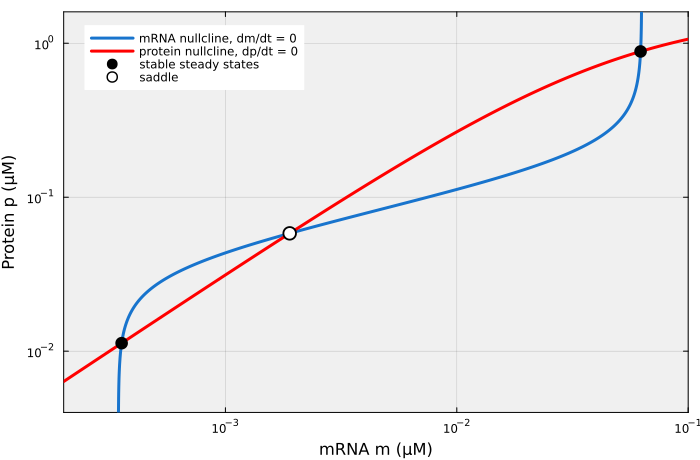

In [6]:
let

    # initialize -
    model = models["positive-autoregulation"];
    gene = model.genes[1];
    γ_m = gene.θ_m + model.μ; # the mRNA loss constant (1/min)
    γ_p = gene.θ_p + model.μ; # the protein loss constant (1/min)
    r_X = gene.Vmax_X * gene.G / (gene.K_X + gene.G); # the transcription rate (µM/min)
    p_grid = 10.0 .^ range(-2.4, 0.2, length = 400); # protein levels (µM)
    m_grid = 10.0 .^ range(-3.7, -1.0, length = 400); # mRNA levels (µM)

    # the mRNA nullcline gives m from p, and the protein nullcline gives p from m -
    m_nullcline = [r_X * transcription_control(model, 1, [0.0, p], 0.0) / γ_m for p ∈ p_grid];
    p_nullcline = [gene.Vmax_L * m / (gene.K_L + m) / γ_p for m ∈ m_grid];

    # the two nullclines -
    plot(m_nullcline, p_grid, lw = 3, c = :dodgerblue3, label = "mRNA nullcline, dm/dt = 0");
    plot!(m_grid, p_nullcline, lw = 3, c = :red, label = "protein nullcline, dp/dt = 0");

    # the steady states, in the color of the legend text: filled when stable, open for the saddle -
    marker_color = current()[1][:legend_font_color]; # black on the light theme, white on the dark theme
    open_color = current()[1][:background_color_subplot]; # the background color fills the open marker
    scatter!([par_states[1][1], par_states[3][1]], [par_states[1][2], par_states[3][2]], ms = 7, c = marker_color, msc = marker_color, label = "stable steady states");
    scatter!([par_states[2][1]], [par_states[2][2]], ms = 7, c = open_color, msc = marker_color, msw = 2, label = "saddle");

    # labels and style: the gray panel is see-through, so the figure works in both themes -
    xlabel!("mRNA m (µM)");
    ylabel!("Protein p (µM)");
    plot!(xscale = :log10, yscale = :log10, xlims = (2e-4, 1e-1), ylims = (4e-3, 1.6),
        background_color_inside = RGBA(0.5, 0.5, 0.5, 0.12), framestyle = :box, fg_legend = :transparent,
        legend = :topleft, size = (700, 460));
end

The S-shaped mRNA nullcline comes from the steep activation, $n=3$. At low protein levels the gene runs on the leak, and at high levels the activator state takes over. The protein nullcline crosses the S three times.

### The Jacobian by Hand
We write the balances of the gene as $\dot{m}=F_{1}(m,p)$ and $\dot{p}=F_{2}(m,p)$:

$$
F_{1}=r_{X}\,\bar{u}(p)-\gamma_{m}\,m,\qquad F_{2}=V^{\max}_{L}\,\frac{m}{K_{L}+m}-\gamma_{p}\,p.
$$

Differentiating each balance with respect to each state gives the Jacobian:

$$
\mathbf{A}=\begin{bmatrix}\dfrac{\partial F_{1}}{\partial m}&\dfrac{\partial F_{1}}{\partial p}\\[8pt]\dfrac{\partial F_{2}}{\partial m}&\dfrac{\partial F_{2}}{\partial p}\end{bmatrix}
=\begin{bmatrix}-\gamma_{m} & r_{X}\,\bar{u}^{\prime}(p)\\[6pt] V^{\max}_{L}\,\dfrac{K_{L}}{(K_{L}+m)^{2}} & -\gamma_{p}\end{bmatrix}.
$$

The lower-left entry comes from the saturating translation rate. The upper-right entry is the feedback of the protein on its own transcription, through the control. With the leak weight $W_{0}$ and the activator weight $W_{1}$, the quotient rule gives:

$$
\bar{u}(p)=\frac{W_{0}+W_{1}f(p)}{1+W_{0}+W_{1}f(p)},\qquad
\bar{u}^{\prime}(p)=\frac{W_{1}\,f^{\prime}(p)}{\left(1+W_{0}+W_{1}f(p)\right)^{2}}.
$$

The bound fraction $f$ depends on the available activator $a=p\,f_{I}$, and the chain rule gives its derivative:

$$
f=\frac{a^{n}}{K^{n}+a^{n}},\qquad
f^{\prime}(p)=\frac{n\,K^{n}a^{n-1}}{\left(K^{n}+a^{n}\right)^{2}}\,f_{I}.
$$

Let's evaluate the hand Jacobian at the three steady states, compare it with the package Jacobian, and compute its eigenvalues:

In [7]:
let

    # initialize: the parameters of gene X -
    model = models["positive-autoregulation"];
    gene = model.genes[1];
    γ_m = gene.θ_m + model.μ; # the mRNA loss constant (1/min)
    γ_p = gene.θ_p + model.μ; # the protein loss constant (1/min)
    r_X = gene.Vmax_X * gene.G / (gene.K_X + gene.G); # the transcription rate (µM/min)
    W₀ = gene.promoter[1].W; # the weight of the leak state
    W₁ = gene.promoter[2].W; # the weight of the activator state
    bound = gene.promoter[2].bound[1]; # protein X, bound in the activator state
    K = bound.K; # the half-binding concentration (µM)
    n = bound.n; # the binding exponent
    I = input_value(model, "I", 0.0); # the inducer concentration (µM)
    f_I = I^bound.n_I / (bound.K_I^bound.n_I + I^bound.n_I); # the fraction of X that carries the inducer
    names = ["low", "middle", "high"];
    differences = Float64[]; # the largest difference from the package Jacobian at each steady state

    # the hand Jacobian at each steady state -
    for i ∈ 1:3
        m = par_states[i][1]; # the mRNA level (µM)
        p = par_states[i][2]; # the protein level (µM)
        a = p * f_I; # the available activator (µM)
        f = a^n / (K^n + a^n); # the bound fraction
        f′ = n * K^n * a^(n - 1) / (K^n + a^n)^2 * f_I; # the derivative of f with respect to p
        ū′ = W₁ * f′ / (1 + W₀ + W₁ * f)^2; # the derivative of the control

        # the four entries of the Jacobian (1/min) -
        A_hand = zeros(2, 2);
        A_hand[1, 1] = -γ_m; # mRNA loss
        A_hand[1, 2] = r_X * ū′; # the feedback of the protein on its own transcription
        A_hand[2, 1] = gene.Vmax_L * gene.K_L / (gene.K_L + m)^2; # the saturating translation rate
        A_hand[2, 2] = -γ_p; # protein loss

        # compare with the package Jacobian, and print the eigenvalues -
        A_package = jacobian(model, par_states[i], 0.0);
        push!(differences, maximum(abs.(A_hand - A_package)));
        λ = eigvals(A_hand);
        println("$(names[i]) state, p = $(round(p; sigdigits = 3)) µM: eigenvalues $(round.(λ; sigdigits = 3)) 1/min, largest difference from the package Jacobian $(round(differences[i]; sigdigits = 2))")
    end

    # checks -
    @test maximum(differences) < 1e-6
end;

low state, p = 0.0113 µM: eigenvalues [-0.292, -0.028] 1/min, largest difference from the package Jacobian 1.0e-11


middle state, p = 0.0582 µM: eigenvalues [-0.354, 0.0335] 1/min, largest difference from the package Jacobian 9.4e-11
high state, p = 0.884 µM: eigenvalues [-0.289, -0.0308] 1/min, largest difference from the package Jacobian 3.1e-11


The hand and package Jacobians agree. The eigenvalues classify the three steady states:

* __Low and high steady states:__ Both eigenvalues are real and negative. These two steady states are stable nodes.
* __Middle steady state:__ One eigenvalue is positive, which makes this steady state a saddle. Here the feedback entry $A_{12}$ is so large that the determinant $\gamma_{m}\gamma_{p}-A_{12}A_{21}$ is negative. A negative determinant gives one positive and one negative eigenvalue.

The saddle separates the two stable states. A small push from the low steady state decays back, and a large enough push carries the gene past the saddle to the high steady state.

___

## Task 3: An Inducer Pulse and the S4 Recursion
In this task, we linearize the gene about its low steady state, with the inducer as the input, and check the step of the S4 recursion against the exact solution of the linear model. Then we compare the linear and nonlinear responses to a small and a large inducer pulse.

### Linearization about the Low State
The state deviation is $\delta\mathbf{x}=(m-m^{\star},\,p-p^{\star})$ at the low steady state $(m^{\star},p^{\star})$. The input deviation is $\delta I=I-I^{\star}$, with the baseline inducer $I^{\star}=1$ µM. In this task, the input of the state space model is $\delta I$, and $\bar{u}$ remains the transcriptional control.

The state matrix $\mathbf{A}$ is the Jacobian at the low steady state, from Task 2. [The `input_jacobian(...)` function](../../../code/src/GeneNetworks.jl) computes the input matrix $\mathbf{B}$, the derivative of the balances with respect to $I$, by a central difference. [The `discretize(...)` function](../../../code/src/GeneNetworks.jl) gives $\bar{\mathbf{A}}$ and $\bar{\mathbf{B}}$ for a step of $\Delta t=1$ min:

In [8]:
(x_low, A, B, Ā, B̄, Δt) = let

    # initialize -
    model = models["positive-autoregulation"];
    x_low = par_states[1]; # the low steady state [m, p] (µM)
    Δt = 1.0; # the time step (min)

    # linearize about the low steady state, with the inducer as the input -
    A = jacobian(model, x_low, 0.0); # the state matrix (1/min)
    B = input_jacobian(model, x_low, 0.0, "I"); # the input matrix (1/min)

    # the bilinear discretization -
    (Ā, B̄) = discretize(A, B; Δt = Δt);
    println("eigenvalues of A: $(round.(eigvals(A); sigdigits = 3)) 1/min")
    println("eigenvalues of Ā: $(round.(eigvals(Ā); sigdigits = 4))")
    println("B = $(round.(B; sigdigits = 3)) 1/min")

    # checks: the low steady state is stable, and so is the recursion -
    @test all(real.(eigvals(A)) .< 0.0)
    @test all(abs.(eigvals(Ā)) .< 1.0)

    (x_low, A, B, Ā, B̄, Δt); # return
end;

eigenvalues of A: [-0.292, -0.028] 1/min


eigenvalues of Ā: [0.7451, 0.9724]
B = [9.08e-6, 0.0] 1/min


Both eigenvalues of $\bar{\mathbf{A}}$ lie inside the unit circle, as the bilinear map predicts for a stable steady state. The second entry of $\mathbf{B}$ is zero, because the inducer acts only on transcription.

### Step Size Check
The trapezoid rule makes the S4 recursion second-order accurate. Halving the step should cut its error by about a factor of four.

For a constant inducer deviation $\delta I$ and $\delta\mathbf{x}(0)=\mathbf{0}$, the linear model has the exact solution $\delta\mathbf{x}(t)=\mathbf{A}^{-1}\left(e^{\mathbf{A}t}-\mathbf{I}\right)\mathbf{B}\,\delta I$. Let's hold the rise of the small pulse, $\delta I=0.1$ µM, for $60$ min, and compare the recursion with steps of $1$ and $0.5$ min against the exact solution:

In [9]:
let

    # initialize -
    δI = 0.1; # the inducer deviation, the rise of the small pulse (µM)
    T = 60.0; # the time the deviation is held, the length of a pulse (min)

    # the exact solution of the linear model at time T; here I is the identity matrix, not the inducer -
    δx_exact = A \ ((exp(A * T) - I) * B) * δI;

    # run the recursion for two step sizes, and print the relative error at time T -
    errors = Float64[];
    for step_size ∈ [1.0, 0.5]
        (Ā_step, B̄_step) = discretize(A, B; Δt = step_size); # the bilinear matrices for this step size
        number_of_steps = round(Int, T / step_size); # the number of steps to reach T
        δx = zeros(2); # the deviation starts at zero
        for k ∈ 1:number_of_steps
            δx = Ā_step * δx + B̄_step * δI; # one step of the recursion
        end
        relative_error = norm(δx - δx_exact) / norm(δx_exact); # the error at T, relative to the exact deviation
        push!(errors, relative_error);
        println("Δt = $(step_size) min: relative error at T = $(round(relative_error; sigdigits = 3))")
    end
    println("error ratio: $(round(errors[1] / errors[2]; sigdigits = 3))")

    # checks: halving the step cuts the error by about four, and the error at Δt = 1 min is small -
    @test isapprox(errors[1] / errors[2], 4.0; rtol = 0.05)
    @test errors[1] < 1e-3
end;

Δt = 1.0 min: relative error at T = 2.85e-5


Δt = 0.5 min: relative error at T = 7.12e-6
error ratio: 4.0


Halving the step cuts the error by a factor of four. At $\Delta t=1$ min, the error is below $0.01\%$ of the exact deviation. We keep this step for the pulse responses.

### Pulse Responses
An inducer pulse raises $I$ from $1$ µM to a higher level from $t=10$ to $t=70$ min, and then returns it to $1$ µM. [The `set_input!(...)` function](../../../code/src/GeneNetworks.jl) sets this schedule on a copy of the model. For each pulse, we run the S4 recursion on the deviations, $\delta\mathbf{x}_{k}=\bar{\mathbf{A}}\,\delta\mathbf{x}_{k-1}+\bar{\mathbf{B}}\,\delta I_{k}$, starting from $\delta\mathbf{x}_{0}=\mathbf{0}$.

[The `balances!(...)` function](../../../code/src/GeneNetworks.jl) evaluates the right-hand sides of the mRNA and protein balances. We solve the nonlinear model with [the `solve(...)` function of the OrdinaryDiffEq package](https://docs.sciml.ai/DiffEqDocs/stable/getting_started/), called as [`OrdinaryDiffEq.solve(...)`](https://docs.sciml.ai/DiffEqDocs/stable/getting_started/) because the course package also has a function with that name. Let's run a small pulse to $1.1$ µM and a large pulse to $5$ µM:

In [10]:
pulses = let

    # initialize -
    model = models["positive-autoregulation"];
    baseline = model.inputs["I"].initial; # the baseline inducer I⋆ (µM)
    t_on = 10.0; # the pulse starts (min)
    t_off = 70.0; # the pulse ends (min)
    T = 480.0; # the final time (min)
    number_of_steps = round(Int, T / Δt); # the number of recursion steps
    levels = [("small", 1.1), ("large", 5.0)]; # the inducer level during each pulse (µM)
    pulses = Dict{String, NamedTuple}(); # pulse name => results

    for (name, level) ∈ levels

        # a copy of the model with the pulse: the level from t_on, and the baseline again from t_off -
        trial = deepcopy(model);
        set_input!(trial, "I", [t_on, t_off], [level, baseline]);

        # the S4 recursion on the deviations from the low steady state -
        t = zeros(number_of_steps + 1); # the times t_k (min)
        I = zeros(number_of_steps + 1); # the inducer at each time (µM)
        p_linear = zeros(number_of_steps + 1); # the protein level of the linear model (µM)
        δx = zeros(2); # the deviation starts at zero
        I[1] = baseline;
        p_linear[1] = x_low[2];
        for k ∈ 1:number_of_steps
            t[k + 1] = k * Δt;
            δI = input_value(trial, "I", t[k]) - baseline; # the inducer deviation over step k
            δx = Ā * δx + B̄ * δI; # one step of the recursion
            p_linear[k + 1] = x_low[2] + δx[2];
            I[k + 1] = input_value(trial, "I", t[k + 1]);
        end

        # the nonlinear balances; tstops makes the solver stop at the pulse edges -
        problem = ODEProblem(balances!, x_low, (0.0, T), trial);
        solution = OrdinaryDiffEq.solve(problem, Tsit5(); tstops = [t_on, t_off], saveat = t, reltol = 1e-8, abstol = 1e-12);
        p_nonlinear = [x[2] for x ∈ solution.u]; # the protein level of the nonlinear model (µM)

        # the peak rise of each model above the low steady state (µM) -
        rise_linear = maximum(p_linear) - x_low[2];
        rise_nonlinear = maximum(p_nonlinear) - x_low[2];

        pulses[name] = (t = t, I = I, p_linear = p_linear, p_nonlinear = p_nonlinear);
        println("$(name) pulse to $(level) µM:")
        println("   peak rise above the low state: linear = $(round(rise_linear; sigdigits = 3)) µM, nonlinear = $(round(rise_nonlinear; sigdigits = 3)) µM")
        println("   final protein: linear = $(round(p_linear[end]; sigdigits = 4)) µM, nonlinear = $(round(p_nonlinear[end]; sigdigits = 4)) µM")
    end

    # checks: the small pulse returns to the low state, and the large pulse switches the gene to the high state -
    @test isapprox(pulses["small"].p_nonlinear[end], x_low[2]; rtol = 1e-3)
    @test isapprox(pulses["large"].p_nonlinear[end], par_states[3][2]; rtol = 1e-2)

    pulses; # return
end;

small pulse to 1.1 µM:


   peak rise above the low state: linear = 8.71e-5 µM, nonlinear = 9.61e-5 µM
   final protein: linear = 0.01127 µM, nonlinear = 0.01127 µM
large pulse to 5.0 µM:
   peak rise above the low state: linear = 0.00349 µM, nonlinear = 0.873 µM
   final protein: linear = 0.01127 µM, nonlinear = 0.8844 µM


After the small pulse, both models return to the low steady state. After the large pulse, the two models end in different steady states. Let's plot the small pulse first:

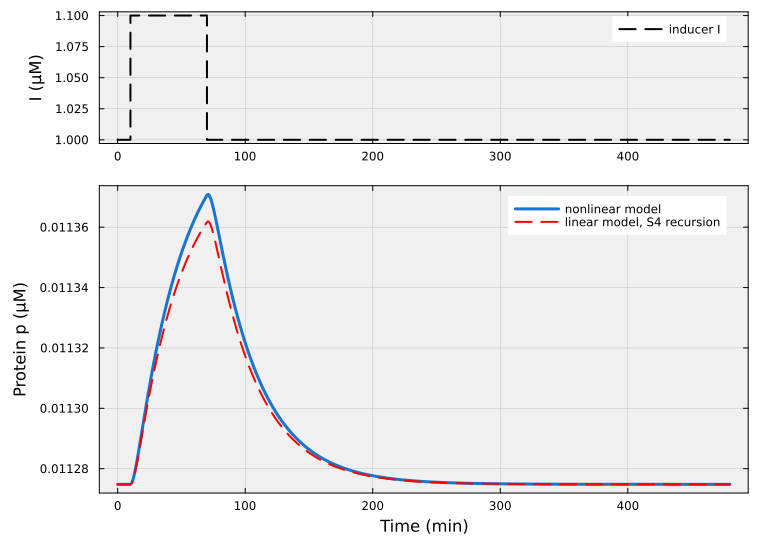

In [11]:
let

    # initialize -
    result = pulses["small"];

    # top panel: the inducer, as a dashed step line in the color of the legend text -
    top = plot();
    inducer_color = top[1][:legend_font_color]; # black on the light theme, white on the dark theme
    plot!(top, result.t, result.I, seriestype = :steppost, lw = 2, ls = :dash, c = inducer_color, label = "inducer I");
    ylabel!(top, "I (µM)");

    # bottom panel: the protein level of the two models -
    bottom = plot(result.t, result.p_nonlinear, lw = 3, c = :dodgerblue3, label = "nonlinear model");
    plot!(bottom, result.t, result.p_linear, lw = 2, ls = :dash, c = :red, label = "linear model, S4 recursion");
    xlabel!(bottom, "Time (min)");
    ylabel!(bottom, "Protein p (µM)");
    plot!(bottom, yformatter = :plain); # plain decimals on the protein axis

    # both panels: the gray panel is see-through, so the figure works in both themes -
    plot(top, bottom, layout = @layout([a{0.3h}; b]), link = :x, size = (760, 540),
        background_color_inside = RGBA(0.5, 0.5, 0.5, 0.12), framestyle = :box, fg_legend = :transparent,
        legend = :topright, left_margin = 4Plots.mm)
end

The linear model follows the shape of the nonlinear response, and its peak rise is about 90% of the nonlinear rise.

At the low steady state, the available activator is far below its half-binding concentration $K$. There, the bound fraction is close to the cubic $(a/K)^{3}$. The linear model replaces that cubic with its tangent line, and the gap between the cubic and the tangent grows with the size of the pulse.

For the large pulse, we also draw the protein level of the middle steady state, the saddle:

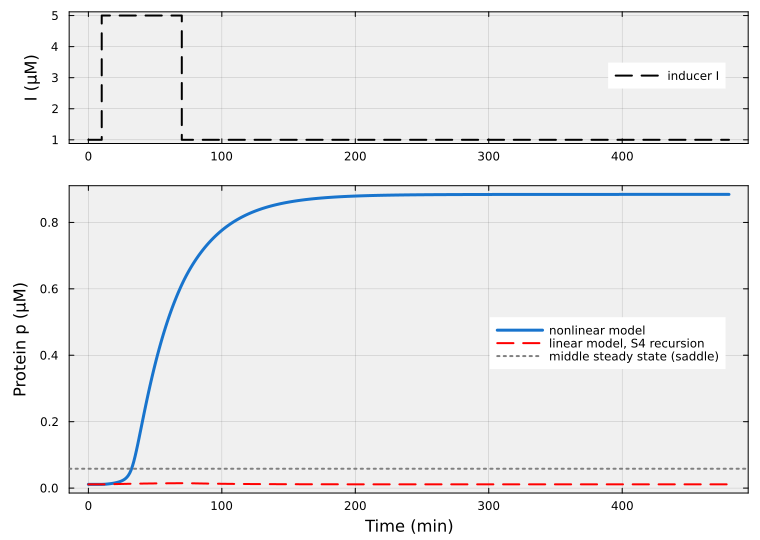

In [12]:
let

    # initialize -
    result = pulses["large"];

    # top panel: the inducer, as a dashed step line in the color of the legend text -
    top = plot();
    inducer_color = top[1][:legend_font_color]; # black on the light theme, white on the dark theme
    plot!(top, result.t, result.I, seriestype = :steppost, lw = 2, ls = :dash, c = inducer_color, label = "inducer I");
    ylabel!(top, "I (µM)");

    # bottom panel: the protein level of the two models -
    bottom = plot(result.t, result.p_nonlinear, lw = 3, c = :dodgerblue3, label = "nonlinear model");
    plot!(bottom, result.t, result.p_linear, lw = 2, ls = :dash, c = :red, label = "linear model, S4 recursion");

    # the protein level of the middle steady state, the saddle -
    hline!(bottom, [par_states[2][2]], lw = 2, ls = :dot, c = :gray, label = "middle steady state (saddle)");
    xlabel!(bottom, "Time (min)");
    ylabel!(bottom, "Protein p (µM)");
    plot!(bottom, yformatter = :plain); # plain decimals on the protein axis

    # both panels: the gray panel is see-through, so the figure works in both themes -
    plot(top, bottom, layout = @layout([a{0.3h}; b]), link = :x, size = (760, 540),
        background_color_inside = RGBA(0.5, 0.5, 0.5, 0.12), framestyle = :box, fg_legend = :transparent,
        legend = :right, left_margin = 4Plots.mm)
end

During the pulse, the protein level of the nonlinear model passes the level of the saddle at about $t=33$ min, and keeps rising after the inducer returns to $1$ µM. The gene settles at its high steady state, near $0.88$ µM. The gene stays on after the pulse ends, which is the memory of the switch.

The linear model describes only small deviations from the low steady state. It predicts a small bump and a return to $0.011$ µM, because it has no saddle and no high steady state.

___

## Summary
In this example, we built three gene network motifs from configuration files, classified their steady states from the eigenvalues of the Jacobian, and compared a linear model of a self-activating gene with the nonlinear model.

> __Key Takeaways:__
>
> * __Configuration files define the networks:__ We built each network from a file that lists its genes, rate constants, and promoter states, and printed the balances that the builder made. One rule for the promoter states gave activation, repression, and the leak.
>
> * __The eigenvalues classify each steady state:__ We found a stable node for negative autoregulation, a saddle between two stable nodes for positive autoregulation, and a decaying oscillation for the negative feedback loop. We derived the Jacobian of the self-activating gene by hand, and it matched the numerical Jacobian.
>
> * __The linear model holds only near its steady state:__ We solved the linearized gene with the S4 recursion, and its peak response to a small inducer pulse came within about 10% of the nonlinear response. A large pulse carried the nonlinear gene past the saddle to its high steady state, which the linear model cannot predict.

We can now change the pulse level, the pulse length, or the binding constants in the configuration file and see where the switching threshold moves.

___